# Exponential Wake Calculations using PyABS


## Scan over W again to determine TCMI Threshold

In [29]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
    
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
from pyabs.core.basis import ABSBasisConfig, build_abs_basis
from pyabs.core.matrix import build_abs_matrix
from pyabs.core.wake import ThetaWake, WakeScale, ExpWake
from pyabs.solvers.eigensolvers import solve_eigenvalues, scan_over_w#, solve_system
from pyabs.solvers.systemsolvers import solve_system

In [31]:
n_max=50
basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=0))

In [33]:
wrange = np.linspace(0.0, 10, num=300)

ans = scan_over_w(basis, wrange=wrange, determine_threshold=True, wake_model=ExpWake(A=1, alpha=0.5))
im_wscan = np.array(np.imag(ans.eigenvalues))
re_wscan = np.array(np.real(ans.eigenvalues))
ans.eigenvalues.shape

Modes 1 and 0 couple at wth = 0.36789297658862874


(300, 101)

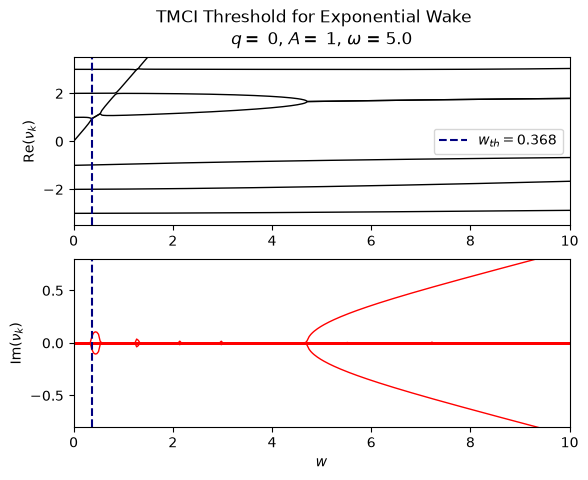

In [36]:
fig, ax = plt.subplots(2)
plt.title(rf"$q = $ 0, $A =$ 1, $\omega$ = 5.0", y = 2.225)
plt.suptitle(rf"TMCI Threshold for Exponential Wake")
ax[0].set_ylim(-3.5,3.5)
ax[1].set_ylim(-0.8,0.8)
ax[1].set_xlim(0.0,10)
ax[0].set_xlim(0.0,10)
ax[1].plot(ans.wake_parameters, im_wscan, color='red', lw=1.0)
ax[0].plot(ans.wake_parameters, re_wscan, color='black', lw=1.0)
ax[0].vlines(ans.threshold, -3.5,3.5, ls = '--', label = rf"$w_{{th}} = {ans.threshold:.03}$", color='navy')
ax[1].vlines(ans.threshold, -0.8,0.8, ls = '--', color='navy')
ax[1].set_ylabel(r"Im($\nu_{k}$)")
ax[0].set_ylabel(r"Re($\nu_{k}$)")
ax[1].set_xlabel(r"$w$")
ax[0].legend()
plt.savefig("../../plots/pyabs_exp.png", dpi=300)
plt.show()

# Test of Stroboscopic Plots and Amplification Factor Calculations

In [39]:
A = 1
alpha = 0.5

matrix = build_abs_matrix(basis, wake_model=ExpWake(A=A, alpha=alpha), scale=WakeScale(w = 1))
solution = solve_system(matrix, A0=1)

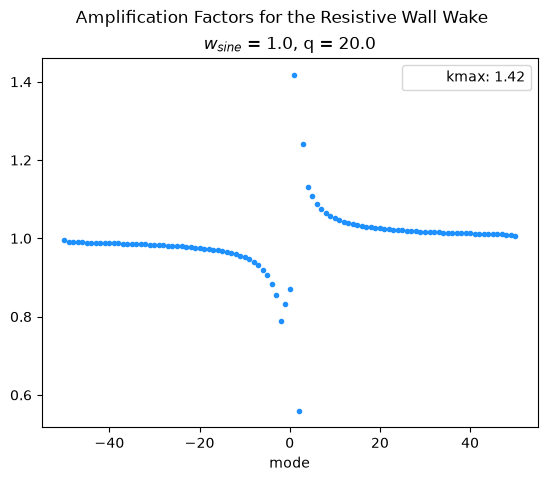

In [40]:
ks, modes = solution.compute_amplification_factors()
kmax = np.max(ks)

fig, ax = plt.subplots()
plt.suptitle(r"Amplification Factors for the Resistive Wall Wake")
plt.title(r"$w_{sine}$ = 1.0, q = 20.0")
plt.scatter(modes, ks, marker='.', color='dodgerblue')
plt.scatter([],[], marker='none',label = f"kmax: {kmax:.2f}")
ax.set_xlabel(r"mode")
#ax.set_ylim(0.8*np.min(ks), kmax+2)
#plt.yscale('log')
plt.legend(loc='upper right')
plt.savefig("../../plots/amplification_factors_sine", dpi=300)
plt.show()

In [45]:
from tqdm.notebook import tqdm
strobo_modes = np.arange(-5,7, dtype = int)
psirange=np.linspace(-np.pi, np.pi, 100)
test = []
with tqdm(total=len(psirange), desc="Solving centroid strobes") as pbar:
    for psi in psirange:
        test.append(solution.compute_centroidstrobe(psi=psi, ns = 20, modes=strobo_modes))
        pbar.update(1)
    pbar.set_postfix(psi=f"{psi:.2f}")
test = np.array(test)
test.shape

Solving centroid strobes:   0%|          | 0/100 [00:00<?, ?it/s]

(100, 12, 20)

IndexError: index 12 is out of bounds for axis 1 with size 12

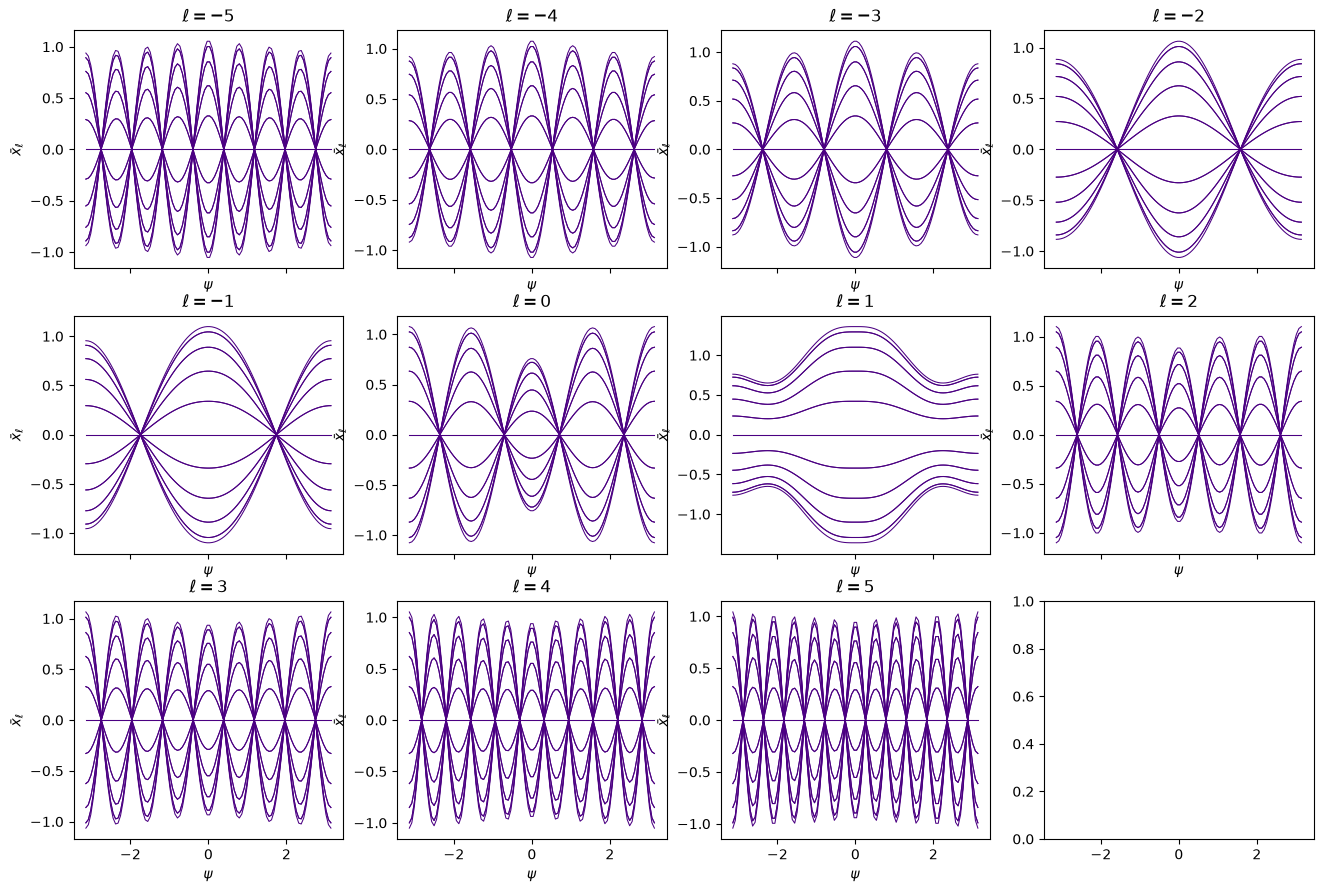

In [48]:
# pick whichever index along the 101 axis you want
sub_max = int(np.ceil((len(strobo_modes)-1)/2))
plot_modes = strobo_modes + n_max
n_size = len(strobo_modes)
ncols = 4
nrows = int(np.ceil(n_size / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), sharex=True, sharey=False)
axes = np.array(axes).reshape(-1)  # flatten in case nrows/ncols > 1
for ax, mode in zip(axes, strobo_modes):
    for k in range(test.shape[2]):
        ydat = test[:, mode+sub_max, k]
        ax.plot(psirange, ydat, color='indigo', lw=0.75)
        #ax.set_ylim(np.min(ydat), np.max(ydat))
    ax.set_title(fr'$\ell = {mode}$')
    #ax.set_ylim(np.min(test[:,mode+n_max,k]), np.max(test[:,mode+n_max,k]))
    ax.set_ylabel(r'$\bar{x}_\ell$')
    ax.set_xlabel(r'$\psi$')

# hide any unused subplot axes if n isn't a perfect multiple of ncols
for ax in axes[n_size:]:
    ax.set_visible(False)

fig.savefig("../../plots/stroboscopic_sine.pdf", bbox_inches='tight')
fig.tight_layout()
plt.show()

In [131]:
%%time
from tqdm.notebook import tqdm
resolution = 50
n_max = 10
n_modes = 2*n_max + 1
omegamax = 25
wmax = 100
qrange = np.linspace(0.0, 50, num=resolution)
omegarange = np.linspace(0.01, np.pi*omegamax, num=resolution)
wrange = np.linspace(0.0, wmax, num=resolution)
imeig_max = np.empty((resolution, resolution, resolution), dtype=float)
log_kmax = np.empty((resolution, resolution, resolution), dtype=float)
'''
for i, q in enumerate(qrange):
    basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=q))
    for j, w in enumerate(wrange):
        theta_wake = ThetaWake(W0=w)
        matrix = build_abs_matrix(basis, wake_model=theta_wake, scale=WakeScale(w = w))
        imeig_max[j][i] = np.max(np.array(np.abs((-1)*solve_eigenvalues(matrix).imag)))
'''

with tqdm(total=resolution * resolution, desc="Solving eigenvalues") as pbar:
    for i, q in enumerate(qrange):
        basis = build_abs_basis(np, ABSBasisConfig(n_max=n_max, q=q))
        for i, omega in enumerate(omegarange):
            for j, w in enumerate(wrange):
                sine_wake = SineWake(A=1, omega=omega)
                matrix = build_abs_matrix(basis, wake_model=sine_wake, scale=WakeScale(w=w))
                solution = solve_system(matrix, A0=1)
                imeig_max[j][i] = np.max(np.array(np.abs(solve_eigenvalues(matrix).imag)))
                log_kmax[j][i] = np.log10(np.max(solution.compute_amplification_factors()))
                
            pbar.update(1)
        pbar.set_postfix(q=f"{q:.1f}")

rows, cols = np.meshgrid(np.arange(resolution), np.arange(resolution), indexing='ij')
df_matrix = pd.DataFrame({
    'source': 'matrix',
    'row': rows.ravel(),
    'col': cols.ravel(),
    'value': imeig_max.ravel()
})

# Arrays as row/value (col left as NaN)
df_arr1 = pd.DataFrame({'source': 'q', 'row': np.arange(resolution), 'col': np.nan, 'value': omegarange})
df_arr2 = pd.DataFrame({'source': 'w', 'row': np.arange(resolution), 'col': np.nan, 'value': wrange})

df_all = pd.concat([df_matrix, df_arr1, df_arr2], ignore_index=True)
#df_all.to_csv(f'../../data/{n_modes}modes_{qmax}qmax_{wmax}wmax_{resolution}reso.csv', index=False)

Solving eigenvalues:   0%|          | 0/2500 [00:00<?, ?it/s]

CPU times: user 1min 32s, sys: 64.3 ms, total: 1min 32s
Wall time: 1min 32s


KeyboardInterrupt: 

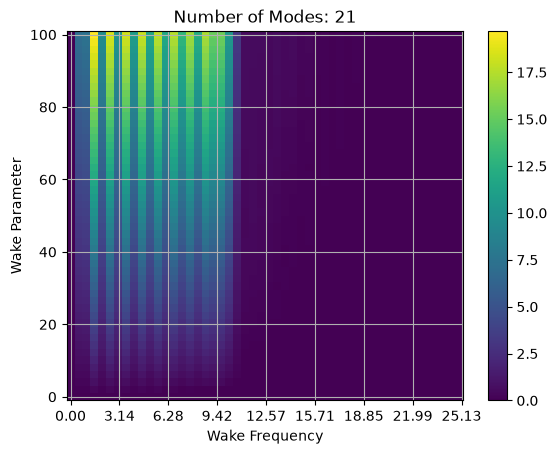

In [126]:
import matplotlib.ticker as ticker
fig, ax = plt.subplots()
cmap = plt.cm.viridis.copy()
cmap.set_bad('black')   
pcm = ax.pcolormesh(omegarange/np.pi, wrange, imeig_max, norm='linear', cmap=cmap)
ax.grid()
ax.set_yscale('linear')
ax.set_xscale('linear')
ax.set_xlabel('Wake Frequency')
ax.set_ylabel('Wake Parameter')
# Set tick frequency/resolution (e.g., a tick every 0.5 units)
ax.xaxis.set_major_locator(ticker.MultipleLocator(np.pi))
plt.title(f"Number of Modes: {2*n_max+1}")
plt.colorbar(pcm, ax=ax)
#plt.savefig("../../plots/tcmi_paramscan_theta")
plt.show()

ValueError: 'c' argument has 2500 elements, which is inconsistent with 'x' and 'y' with size 125000.

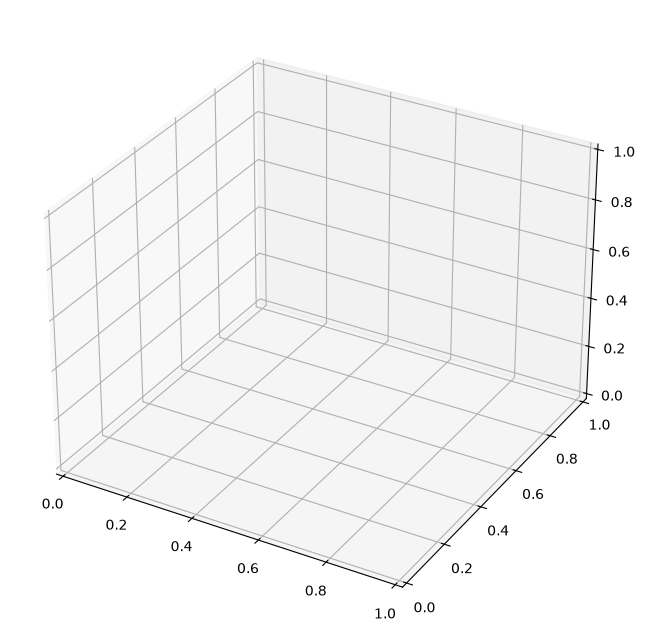

In [130]:
# Flatten everything for scatter plotting
W, Q, OMEG = np.meshgrid(wrange, qrange, omegarange, indexing='ij')
wrange_flat = W.ravel()
sc_flat = Q.ravel()
omeg_flat = OMEG.ravel()
imeig_flat = imeig_max.ravel()
kmax_flat= log_kmax.ravel()

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(wrange_flat, sc_flat, omeg_flat, c=imeig_flat, cmap='viridis', s=20)

ax.set_xlabel('w')
ax.set_ylabel('q')
ax.set_zlabel('l')

cbar = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1)
cbar.set_label('f(w, q, l)')

plt.tight_layout()
plt.show()